# 9. Capstone: a reproducible spatial evidence brief

**Question:** How sensitive is a prioritization map to the definition of “high”?
**Objectives:** connect a map to a transparent rule, compare thresholds, quantify instability,
and report limits. **Time:** 45–60 minutes. **Prerequisites:** Chapters 1–8.

A fictional environmental index is observed at 100 regular grid sites. It has arbitrary units
and no validated relationship with health, risk, or policy. Thresholds are teaching choices.
The target is a descriptive ranking of these sites, not an estimate of a real population effect.
[Open in Lab](https://jltobias.github.io/JupyterLite-R/lite/lab/index.html?path=09-capstone.ipynb)

In [1]:
# Project: JupyterLite-R | Chapter 09 | Purpose: reproducible sensitivity exercise.
# Author: project contributors with Codex | Contact: repository Issues.
# Created/updated: 2026-11-16 | Inputs: original simulation | Outputs: maps, sensitivity table.
# Dependencies: base R; optional ggplot2. Change log: initial lesson.
set.seed(20261116)
sites <- expand.grid(x = 1:10, y = 1:10)
sites$id <- sprintf("P%03d", 1:100)
sites$index <- with(sites, 40 + 15 * exp(-((x-7)^2 + (y-6)^2)/8) + rnorm(100, sd = 2))
stopifnot(nrow(sites) == 100, !anyDuplicated(sites$id), !anyNA(sites))
thresholds <- c(45, 48, 51)
sensitivity <- data.frame(threshold = thresholds,
  selected_sites = vapply(thresholds, function(cutoff) sum(sites$index >= cutoff), integer(1)))
stopifnot(all(diff(sensitivity$selected_sites) <= 0))
print(sensitivity)

  threshold selected_sites
1        45             33
2        48             16
3        51              8


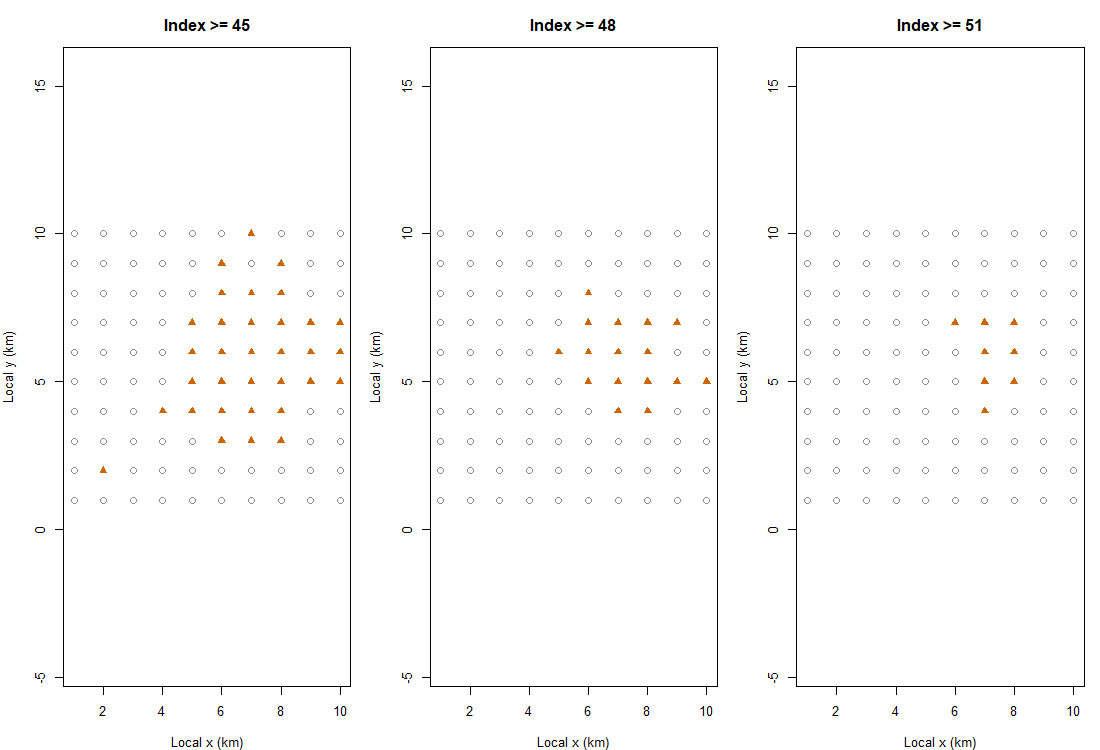

In [2]:
par(mfrow = c(1,3), mar = c(4,4,3,1))
for (cutoff in thresholds) {
  selected <- sites$index >= cutoff
  plot(sites$x, sites$y, asp = 1, pch = ifelse(selected,17,1),
       col = ifelse(selected,"darkorange3","grey55"), cex = 1.1,
       xlab = "Local x (km)", ylab = "Local y (km)", main = paste("Index >=",cutoff))
}
par(mfrow = c(1,1))

## A package-based data visualization
If installed, `ggplot2` provides a second representation. The value mapping is explicit,
and highlighted sites have a different shape as well as color. This is a scatter map of
sample locations; it does not imply that each point represents a polygon or raster cell.

In [ ]:
if (requireNamespace("ggplot2", quietly = TRUE)) {
  sites$selected <- sites$index >= 48
  figure <- ggplot2::ggplot(sites, ggplot2::aes(x, y, color = index, shape = selected)) +
    ggplot2::geom_point(size = 3) + ggplot2::coord_equal() +
    ggplot2::scale_color_viridis_c() + ggplot2::theme_minimal() +
    ggplot2::labs(title = "Fictional environmental index", color = "Arbitrary units",
      shape = "Index >= 48", x = "Local x (km)", y = "Local y (km)")
  print(figure)
} else message("Optional ggplot2 view skipped: package not installed. Try webr::install('ggplot2').")

In [3]:
# Sensitivity to additive measurement perturbations, NOT a confidence interval.
B <- 200L
selection_frequency <- rowMeans(replicate(B, sites$index + rnorm(100, sd = 2) >= 48))
sites$selection_frequency <- selection_frequency
stopifnot(all(selection_frequency >= 0 & selection_frequency <= 1))
print(head(sites[order(abs(sites$index - 48)), ], 10), row.names = FALSE)

  x y   id    index selection_frequency
  7 3 P027 47.72634               0.455
  8 9 P088 47.34051               0.420
  9 5 P049 48.77000               0.675
  9 7 P069 48.81249               0.635
  7 8 P077 47.14480               0.360
 10 5 P050 48.93472               0.675
  4 4 P034 46.96456               0.270
 10 7 P070 46.94612               0.265
  8 4 P038 49.06591               0.690
  9 6 P059 46.78336               0.255


## Your evidence brief
Deliver a notebook with: a question; a data and units inventory; two map choices; the threshold
table; a sensitivity result; a text alternative; citations; and `sessionInfo()`. State what would
be required to replace this simulation with appropriately licensed observations. Preserve missing
values, audit keys, and justify the coordinate system before analysis.

**Assessment:** reproducibility (25%); correct geography, units, and joins (25%); honest uncertainty
and interpretation (25%); readable maps and attribution (25%).
**Checkpoint:** higher thresholds cannot select more sites; near-threshold sites generally change
classification more often. Perturbation frequency is conditional on a chosen noise model, not a
probability that a site is truly unsafe. No causal or policy conclusion follows from this exercise.

## Next chapters to develop
Explore `gstat` for variograms and spatial validation, `sfnetworks` for network distance, `stars`
for data cubes, and `tmap`/`leaflet` for web cartography. Verify each WebAssembly build and renderer
before promoting an extension to a browser-tested lesson. Heavy raster processing and external
system dependencies may require desktop R. Use the R-spatial directory and CRAN task views to
find maintained tools; a directory listing is not a browser compatibility guarantee.

## Sources
[ggplot2 reference](https://ggplot2.tidyverse.org/reference/);
[R-spatial projects](https://r-spatial.org/projects/);
[CRAN Spatial Task View](https://cran.r-project.org/view=Spatial).

In [4]:
sessionInfo()

R version 4.6.0 (2026-04-24 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26100)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] C
system code page: 65001

time zone: America/New_York
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
[1] compiler_4.6.0
